# Airport / Passport Domain Information Extraction — Backend Development

This notebook develops and validates, stage by stage, the NLP pipeline used by the
Streamlit app (`app.py`). Each stage is built here first with visible intermediate
output, then consolidated into `backend/pipeline.py`, which the app imports directly.

**Pipeline stages**
1. Load spaCy + register a domain `EntityRuler` (airport/passport vocabulary)
2. POS tagging
3. Named Entity Recognition (generic + domain-specific)
4. Relation extraction (dependency-rule based)
5. Event extraction (trigger lexicon)
6. Temporal ordering (absolute time + discourse cues → NetworkX graph)
7. Wikidata enrichment (SPARQL/REST lookup for real-world entities)

**Domain corpus:** synthetic airport/passport narrative text (no real personal
documents are used — passport numbers, names etc. are fabricated for demonstration).


In [1]:
import sys
sys.path.insert(0, '.')  # backend/ itself, if running notebook from backend/
import pandas as pd
import spacy
from spacy.pipeline import EntityRuler
import networkx as nx
import matplotlib.pyplot as plt

pd.set_option('display.max_colwidth', 80)
print(spacy.__version__)


3.7.5


## 1. Sample corpus
A short synthetic narrative covering the passenger journey: passport/visa issuance → check-in → security → immigration → boarding → departure → arrival → customs.

In [2]:
with open('../sample_data/sample_corpus.txt') as f:
    text = f.read()
print(text)


Ravi Kumar, an Indian national, holds passport number K1234567, issued on 5 January 2020 by the Regional Passport Office, Delhi. He also carries a tourist visa for the United Arab Emirates, granted on 10 February 2024. On 12 March 2024, Ravi checked in at Indira Gandhi International Airport for flight AI202 to Dubai. After check-in, he went through security screening at Terminal 3. Following the security check, Ravi cleared immigration at the passport control counter. He then proceeded to Gate 14 for boarding. Boarding for flight AI202 began at 6:30 pm. The flight departed at 7:15 pm on 12 March 2024. Air India operates the AI202 route between Delhi and Dubai. Ravi arrived at Dubai International Airport at 9:45 pm local time. After arrival, he cleared customs and collected his baggage. Emirates staff assisted passengers connecting to onward flights. Priya Sharma, his colleague, boarded a separate flight, 6E345, operated by IndiGo, departing from Terminal 2 an hour earlier.



## 2. Load spaCy + domain EntityRuler

The base `en_core_web_sm` model recognizes generic entities well (PERSON, GPE, DATE)
but fails on domain vocabulary — a flight number like `AI202` gets tagged `PRODUCT`,
`Gate 14` gets tagged `ORG`. We add an `EntityRuler` **before** the statistical NER
component with `overwrite_ents=True` so high-precision regex/token patterns for
passport numbers, flight numbers, gates, terminals, seats, visa types and airports
take priority.

In [3]:
nlp = spacy.load('en_core_web_sm')

DOMAIN_PATTERNS = [
    {"label": "PASSPORT_NO", "pattern": [{"TEXT": {"REGEX": r"^[A-PR-WYa-pr-wy][0-9]{6,8}$"}}]},
    {"label": "PASSPORT_NO", "pattern": [{"TEXT": {"REGEX": r"^[A-Za-z]{2}[0-9]{6,7}$"}}]},
    {"label": "FLIGHT_NO", "pattern": [{"TEXT": {"REGEX": r"^[A-Za-z][A-Za-z0-9][- ]?\d{2,4}$"}}]},
    {"label": "FLIGHT_NO", "pattern": [{"TEXT": {"REGEX": r"^\d[A-Za-z][- ]?\d{2,4}$"}}]},
    {"label": "GATE", "pattern": [{"LOWER": "gate"}, {"TEXT": {"REGEX": r"^[A-Z0-9]{1,3}$"}}]},
    {"label": "TERMINAL", "pattern": [{"LOWER": "terminal"}, {"TEXT": {"REGEX": r"^[A-Z0-9]{1,2}$"}}]},
    {"label": "SEAT", "pattern": [{"LOWER": "seat"}, {"TEXT": {"REGEX": r"^\d{1,2}[A-K]$"}}]},
    {"label": "VISA_TYPE", "pattern": [{"LOWER": {"IN": ["tourist", "business", "transit", "student", "work"]}}, {"LOWER": "visa"}]},
    {"label": "DOCUMENT", "pattern": [{"LOWER": "boarding"}, {"LOWER": "pass"}]},
    {"label": "DOCUMENT", "pattern": [{"LOWER": "passport"}]},
    {"label": "DOCUMENT", "pattern": [{"LOWER": "visa"}]},
    {"label": "AIRPORT", "pattern": [{"IS_TITLE": True, "OP": "+"}, {"LOWER": "international"}, {"LOWER": "airport"}]},
    {"label": "AIRPORT", "pattern": [{"IS_TITLE": True, "OP": "+"}, {"LOWER": "airport"}]},
]

ruler = nlp.add_pipe("entity_ruler", before="ner", config={"overwrite_ents": True})
ruler.add_patterns(DOMAIN_PATTERNS)
nlp.pipe_names


['tok2vec',
 'tagger',
 'parser',
 'attribute_ruler',
 'lemmatizer',
 'entity_ruler',
 'ner']

In [4]:
doc = nlp(text)
print(f"{len(list(doc.sents))} sentences, {len(doc)} tokens")


13 sentences, 188 tokens


## 3. POS Tagging
Using spaCy's statistical tagger (`token.pos_` = universal tag, `token.tag_` = fine-grained Penn Treebank tag) plus dependency labels, which relation extraction (step 5) relies on.

In [5]:
pos_rows = [{"token": t.text, "lemma": t.lemma_, "pos": t.pos_, "tag": t.tag_, "dep": t.dep_, "head": t.head.text}
            for t in doc if not t.is_space]
pos_df = pd.DataFrame(pos_rows)
pos_df.head(15)


,token,lemma,pos,tag,dep,head
0,Ravi,Ravi,PROPN,NNP,compound,Kumar
1,Kumar,Kumar,PROPN,NNP,nsubj,holds
2,",",",",PUNCT,",",punct,Kumar
3,an,an,DET,DT,det,national
4,Indian,indian,ADJ,JJ,amod,national
5,national,national,ADJ,JJ,appos,Kumar
6,",",",",PUNCT,",",punct,Kumar
7,holds,hold,VERB,VBZ,ROOT,holds
8,passport,passport,NOUN,NN,compound,number
9,number,number,NOUN,NN,compound,K1234567


## 4. Named Entity Recognition
Combines spaCy's default entities (PERSON, GPE, ORG, DATE, TIME, NORP) with the domain EntityRuler labels (PASSPORT_NO, FLIGHT_NO, GATE, TERMINAL, SEAT, VISA_TYPE, DOCUMENT, AIRPORT).

A small post-processing heuristic also resolves repeated bare first-name mentions (e.g. a second, unqualified 'Ravi') back to `PERSON` when the base model mis-tags them — this is a simple form of name coreference resolution.

In [6]:
from spacy.tokens import Span

def resolve_repeated_person_mentions(doc):
    known_name_parts = set()
    for ent in doc.ents:
        if ent.label_ == "PERSON" and len(ent) > 1:
            known_name_parts.update(part.text for part in ent)
    new_ents = []
    for ent in doc.ents:
        if len(ent) == 1 and ent.text in known_name_parts and ent.label_ != "PERSON":
            new_ents.append(Span(doc, ent.start, ent.end, label="PERSON"))
        else:
            new_ents.append(ent)
    doc.ents = new_ents
    return doc

doc = resolve_repeated_person_mentions(doc)
ent_df = pd.DataFrame([{"text": e.text, "label": e.label_, "sentence": e.sent.text.strip()} for e in doc.ents])
ent_df


,text,label,sentence
0,Ravi Kumar,PERSON,"Ravi Kumar, an Indian national, holds passport number K1234567, issued on 5 ..."
1,Indian,NORP,"Ravi Kumar, an Indian national, holds passport number K1234567, issued on 5 ..."
2,passport,DOCUMENT,"Ravi Kumar, an Indian national, holds passport number K1234567, issued on 5 ..."
3,K1234567,PASSPORT_NO,"Ravi Kumar, an Indian national, holds passport number K1234567, issued on 5 ..."
4,5 January 2020,DATE,"Ravi Kumar, an Indian national, holds passport number K1234567, issued on 5 ..."
5,the Regional,ORG,"Ravi Kumar, an Indian national, holds passport number K1234567, issued on 5 ..."
6,Passport,DOCUMENT,"Ravi Kumar, an Indian national, holds passport number K1234567, issued on 5 ..."
7,Delhi,GPE,"Ravi Kumar, an Indian national, holds passport number K1234567, issued on 5 ..."
8,tourist visa,VISA_TYPE,"He also carries a tourist visa for the United Arab Emirates, granted on 10 F..."
9,the United Arab Emirates,GPE,"He also carries a tourist visa for the United Arab Emirates, granted on 10 F..."


In [7]:
ent_df['label'].value_counts()


label
GPE            5
PERSON         4
DATE           4
FLIGHT_NO      4
DOCUMENT       3
TIME           3
ORG            2
AIRPORT        2
TERMINAL       2
NORP           1
PASSPORT_NO    1
VISA_TYPE      1
GATE           1
Name: count, dtype: int64

## 5. Relation Extraction (dependency-rule based)

For each verb whose lemma is in a small domain lexicon (`hold → HOLDS_DOCUMENT`,
`board → BOARDS`, `depart → DEPARTS_FROM`, `arrive → ARRIVES_AT`, `issue → ISSUED_BY`, ...),
we pull the nominal subject (`nsubj`) as the source argument and the direct object /
prepositional object as the target argument, then map each argument to the entity
span that contains it (falling back to raw token text/POS if no entity covers it).
Any other subject-verb-object triple is captured generically as `RELATED_TO` to keep recall reasonable.

In [8]:
RELATION_VERBS = {
    "hold": "HOLDS_DOCUMENT", "carry": "HOLDS_DOCUMENT", "present": "PRESENTS_DOCUMENT",
    "board": "BOARDS", "depart": "DEPARTS_FROM", "arrive": "ARRIVES_AT",
    "issue": "ISSUED_BY", "check": "CHECKS_IN_AT", "screen": "SCREENED_AT",
    "clear": "CLEARED_AT", "travel": "TRAVELS_TO", "fly": "FLIES_ON",
    "land": "LANDS_AT", "belong": "NATIONALITY_OF", "assign": "ASSIGNED",
}

def find_entity_span(doc, token):
    for ent in doc.ents:
        if ent.start <= token.i < ent.end:
            return ent
    return None

def extract_relations(doc):
    rows = []
    for sent in doc.sents:
        for tok in sent:
            if tok.pos_ != "VERB":
                continue
            subj = [c for c in tok.children if c.dep_ in ("nsubj", "nsubjpass")]
            objs = [c for c in tok.children if c.dep_ in ("dobj", "attr", "oprd")]
            preps = [c for c in tok.children if c.dep_ == "prep"]
            for p in preps:
                objs += [c for c in p.children if c.dep_ == "pobj"]
            if not subj or not objs:
                continue
            relation = RELATION_VERBS.get(tok.lemma_.lower(), "RELATED_TO")
            for s in subj:
                for o in objs:
                    s_ent, o_ent = find_entity_span(doc, s), find_entity_span(doc, o)
                    rows.append({
                        "subject": s_ent.text if s_ent else s.text,
                        "relation": relation,
                        "object": o_ent.text if o_ent else o.text,
                        "sentence": sent.text.strip(),
                    })
    return pd.DataFrame(rows)

rel_df = extract_relations(doc)
rel_df


,subject,relation,object,sentence
0,Ravi Kumar,HOLDS_DOCUMENT,K1234567,"Ravi Kumar, an Indian national, holds passport number K1234567, issued on 5 ..."
1,He,HOLDS_DOCUMENT,tourist visa,"He also carries a tourist visa for the United Arab Emirates, granted on 10 F..."
2,Ravi,CHECKS_IN_AT,12 March 2024,"On 12 March 2024, Ravi checked in at Indira Gandhi International Airport for..."
3,Ravi,CHECKS_IN_AT,Indira Gandhi International Airport,"On 12 March 2024, Ravi checked in at Indira Gandhi International Airport for..."
4,Ravi,CHECKS_IN_AT,AI202,"On 12 March 2024, Ravi checked in at Indira Gandhi International Airport for..."
5,Ravi,CHECKS_IN_AT,Dubai,"On 12 March 2024, Ravi checked in at Indira Gandhi International Airport for..."
6,he,RELATED_TO,check,"After check-in, he went through security screening at Terminal 3."
7,he,RELATED_TO,screening,"After check-in, he went through security screening at Terminal 3."
8,Ravi,CLEARED_AT,immigration,"Following the security check, Ravi cleared immigration at the passport contr..."
9,Ravi,CLEARED_AT,check,"Following the security check, Ravi cleared immigration at the passport contr..."


## 6. Event Extraction

A trigger-word lexicon maps surface phrases to canonical airport-domain event types
(`CHECK_IN`, `SECURITY_SCREENING`, `IMMIGRATION_CLEARANCE`, `BOARDING`, `DEPARTURE`,
`ARRIVAL`, `CUSTOMS`, `BAGGAGE_CLAIM`, `PASSPORT_ISSUANCE`, `VISA_ISSUANCE`). For every
sentence containing a trigger, we attach: the nearest `DATE`/`TIME` entity in that
sentence (parsed to a `datetime` where possible via `dateutil`), and all other entities
in the sentence as event participants.

In [9]:
import re
from dataclasses import dataclass, field
from datetime import datetime
from dateutil import parser as dateparser

EVENT_TRIGGERS = {
    "PASSPORT_ISSUANCE": ["issued", "issuance"],
    "VISA_ISSUANCE": ["granted", "visa issued", "visa granted"],
    "CHECK_IN": ["check-in", "checked in", "check in", "checking in"],
    "SECURITY_SCREENING": ["security screening", "screened", "security check"],
    "IMMIGRATION_CLEARANCE": ["immigration", "passport control", "clearance", "cleared"],
    "BOARDING": ["boarding", "boarded", "board"],
    "DEPARTURE": ["departure", "departed", "took off", "depart"],
    "ARRIVAL": ["arrival", "arrived", "landed", "arrive"],
    "CUSTOMS": ["customs"],
    "BAGGAGE_CLAIM": ["baggage claim", "collected baggage", "collected his bag", "collected her bag"],
}

@dataclass
class Event:
    event_type: str
    trigger: str
    sentence: str
    sent_index: int
    time_expr: str = None
    time_parsed: datetime = None
    participants: list = field(default_factory=list)

def extract_events(doc):
    events = []
    for sent_idx, sent in enumerate(doc.sents):
        low = sent.text.lower()
        for event_type, triggers in EVENT_TRIGGERS.items():
            for trig in triggers:
                if trig in low:
                    time_expr, time_parsed = None, None
                    for ent in sent.ents:
                        if ent.label_ in ("DATE", "TIME"):
                            time_expr = ent.text
                            try:
                                time_parsed = dateparser.parse(ent.text, fuzzy=True, default=datetime(2024,1,1))
                            except Exception:
                                pass
                            break
                    participants = [e.text for e in sent.ents if e.label_ not in ("DATE", "TIME")]
                    events.append(Event(event_type, trig, sent.text.strip(), sent_idx, time_expr, time_parsed, participants))
                    break
    return events

events = extract_events(doc)
event_df = pd.DataFrame([{"event_type": e.event_type, "trigger": e.trigger, "time_expr": e.time_expr,
                           "time_parsed": e.time_parsed, "participants": ", ".join(e.participants),
                           "sent_index": e.sent_index} for e in events])
event_df


,event_type,trigger,time_expr,time_parsed,participants,sent_index
0,PASSPORT_ISSUANCE,issued,5 January 2020,2020-01-05 00:00:00,"Ravi Kumar, Indian, passport, K1234567, the Regional, Passport, Delhi",0
1,VISA_ISSUANCE,granted,10 February 2024,2024-02-10 00:00:00,"tourist visa, the United Arab Emirates",1
2,CHECK_IN,checked in,12 March 2024,2024-03-12 00:00:00,"Ravi, Indira Gandhi International Airport, AI202, Dubai",2
3,CHECK_IN,check-in,NaN,NaT,Terminal 3,3
4,SECURITY_SCREENING,security screening,NaN,NaT,Terminal 3,3
5,SECURITY_SCREENING,security check,NaN,NaT,"Ravi, passport",4
6,IMMIGRATION_CLEARANCE,immigration,NaN,NaT,"Ravi, passport",4
7,BOARDING,boarding,NaN,NaT,Gate 14,5
8,BOARDING,boarding,6:30 pm,2024-01-01 18:30:00,AI202,6
9,DEPARTURE,departed,7:15 pm,2024-01-01 19:15:00,,7


## 7. Temporal Ordering

We build a directed graph (`networkx.DiGraph`) over extracted events. Edge `A → B`
means "A happens before B". Two signal sources feed the graph:

1. **Absolute timestamps** — events with a parsed `time_parsed` are sorted chronologically and chained.
2. **Discourse cues** — words like *after/following/then* (→ forward edge) or *before/prior to* (→ backward edge) link adjacent event-bearing sentences when no timestamp is available.

Where neither signal exists, we fall back to narrative (sentence) order, since travel
narratives are normally told chronologically. The graph is then topologically sorted
to produce a single best-effort timeline.

In [10]:
CUE_BEFORE = {"before", "prior to", "ahead of"}
CUE_AFTER = {"after", "following", "once", "subsequently", "then", "later"}

def build_temporal_graph(events):
    G = nx.DiGraph()
    for i, e in enumerate(events):
        node_id = f"{i}:{e.event_type}"
        G.add_node(node_id, event_type=e.event_type, sentence=e.sentence,
                   time_parsed=e.time_parsed, sent_index=e.sent_index)
    nodes = list(G.nodes(data=True))
    timed = [(n, d) for n, d in nodes if d["time_parsed"]]
    timed.sort(key=lambda x: x[1]["time_parsed"])
    for (n1, _), (n2, _) in zip(timed, timed[1:]):
        G.add_edge(n1, n2, reason="chronological_time")
    for (n1, d1), (n2, d2) in zip(nodes, nodes[1:]):
        low = d2["sentence"].lower()
        if any(c in low for c in CUE_AFTER) and not G.has_edge(n1, n2):
            G.add_edge(n1, n2, reason="discourse_cue_after")
        elif any(c in low for c in CUE_BEFORE) and not G.has_edge(n2, n1):
            G.add_edge(n2, n1, reason="discourse_cue_before")
        elif not G.has_edge(n1, n2) and not G.has_edge(n2, n1):
            G.add_edge(n1, n2, reason="narrative_order")
    return G

G = build_temporal_graph(events)
try:
    order = list(nx.topological_sort(G))
except nx.NetworkXUnfeasible:
    order = sorted(G.nodes(), key=lambda n: G.nodes[n]["sent_index"])

for n in order:
    print(f"{n:30s} | {G.nodes[n]['sentence'][:70]}")


0:PASSPORT_ISSUANCE            | Ravi Kumar, an Indian national, holds passport number K1234567, issued
1:VISA_ISSUANCE                | He also carries a tourist visa for the United Arab Emirates, granted o
2:CHECK_IN                     | On 12 March 2024, Ravi checked in at Indira Gandhi International Airpo
3:CHECK_IN                     | After check-in, he went through security screening at Terminal 3.
4:SECURITY_SCREENING           | After check-in, he went through security screening at Terminal 3.
5:SECURITY_SCREENING           | Following the security check, Ravi cleared immigration at the passport
6:IMMIGRATION_CLEARANCE        | Following the security check, Ravi cleared immigration at the passport
7:BOARDING                     | He then proceeded to Gate 14 for boarding.
8:BOARDING                     | Boarding for flight AI202 began at 6:30 pm.
9:DEPARTURE                    | The flight departed at 7:15 pm on 12 March 2024.
10:ARRIVAL                     | Ravi arrived a

/tmp/ipykernel_617/2584585415.py:6: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


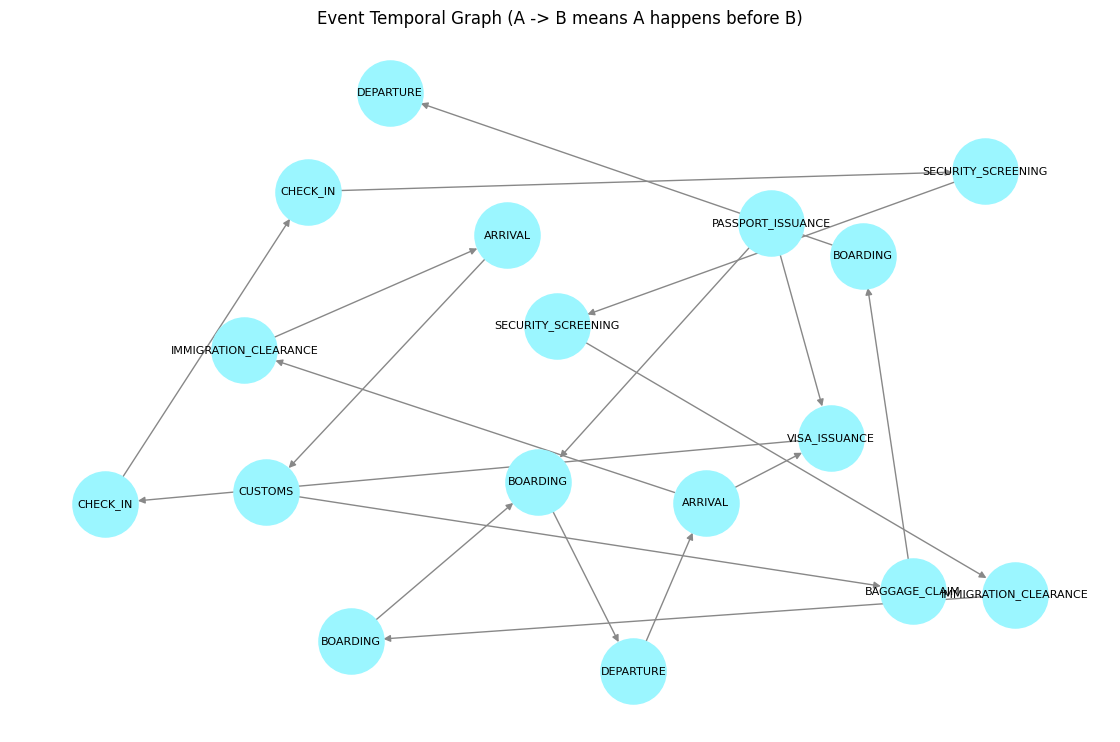

In [11]:
plt.figure(figsize=(11, 7))
pos = nx.spring_layout(G, k=1.2, seed=42)
labels = {n: G.nodes[n]['event_type'] for n in G.nodes}
nx.draw(G, pos, labels=labels, node_color='#9bf6ff', node_size=2200, font_size=8, arrows=True, edge_color='#888')
plt.title("Event Temporal Graph (A -> B means A happens before B)")
plt.tight_layout()
plt.savefig('../outputs/temporal_graph.png', dpi=150)
plt.show()


## 8. Wikidata Enrichment

Real-world named entities (countries, organizations, airports, nationalities) are
linked to Wikidata via the public `wbsearchentities` REST API, returning a QID and a
short description. This grounds extracted entities in a structured knowledge base —
useful for downstream disambiguation (e.g. confirming "Dubai" refers to the city,
not the emirate) and for enriching the entity table with canonical descriptions.

A small offline fallback dictionary is included so the pipeline still runs in
environments without internet access (e.g. this sandboxed notebook execution) —
the Streamlit app, run with normal internet access, will hit the live API.

In [12]:
import requests

WIKIDATA_SEARCH_URL = "https://www.wikidata.org/w/api.php"

def wikidata_lookup(entity_text, timeout=4.0):
    try:
        resp = requests.get(WIKIDATA_SEARCH_URL, params={
            "action": "wbsearchentities", "search": entity_text,
            "language": "en", "format": "json", "limit": 1,
        }, timeout=timeout)
        resp.raise_for_status()
        results = resp.json().get("search", [])
        if results:
            top = results[0]
            return {"entity": entity_text, "qid": top.get("id"),
                    "description": top.get("description", ""), "source": "live"}
    except Exception as e:
        print(f"  (live lookup unavailable for '{entity_text}': {e})")
    return {"entity": entity_text, "qid": None, "description": None, "source": "unavailable"}

# Try a couple of live lookups (will show 'unavailable' in network-restricted sandboxes)
for name in ["Dubai", "India", "Air India"]:
    print(wikidata_lookup(name))


  (live lookup unavailable for 'Dubai': 403 Client Error: Forbidden for url: https://www.wikidata.org/w/api.php?action=wbsearchentities&search=Dubai&language=en&format=json&limit=1)
{'entity': 'Dubai', 'qid': None, 'description': None, 'source': 'unavailable'}
  (live lookup unavailable for 'India': 403 Client Error: Forbidden for url: https://www.wikidata.org/w/api.php?action=wbsearchentities&search=India&language=en&format=json&limit=1)
{'entity': 'India', 'qid': None, 'description': None, 'source': 'unavailable'}
  (live lookup unavailable for 'Air India': 403 Client Error: Forbidden for url: https://www.wikidata.org/w/api.php?action=wbsearchentities&search=Air+India&language=en&format=json&limit=1)
{'entity': 'Air India', 'qid': None, 'description': None, 'source': 'unavailable'}


> **Note:** this notebook was developed in a network-restricted sandbox, so the
> live Wikidata calls above may show `source: unavailable`. `backend/pipeline.py`
> includes a small offline fallback dictionary for exactly this case, and the
> Streamlit app will use live results automatically when run with normal internet
> access.

## 9. Consolidation

All of the logic above has been consolidated into `backend/pipeline.py` as the single
importable module `run_pipeline(text)`, which the Streamlit app (`app.py`) calls
directly. The cell below imports it and confirms the packaged version reproduces
the same results as this notebook.

In [13]:
import sys
sys.path.insert(0, '.')
from pipeline import run_pipeline

result = run_pipeline(text, enrich_wikidata=False)
print("Entities:", len(result['entities_df']))
print("Relations:", len(result['relations_df']))
print("Events:", len(result['events_df']))
print("Temporal order (first 5):", result['temporal_order'][:5])


Entities: 33
Relations: 23
Events: 17
Temporal order (first 5): ['0:PASSPORT_ISSUANCE', '1:VISA_ISSUANCE', '2:CHECK_IN', '3:CHECK_IN', '4:SECURITY_SCREENING']
